# NLP Lab6 — Encoder–Decoder (seq2seq) และ Attention

## เป้าหมายของ Lab นี้

สร้างระบบแปลภาษา **ไทย → อังกฤษ** ด้วยมือทั้งระบบ แล้ว **พิสูจน์ด้วยข้อมูลของตัวเอง**
ว่าสิ่งที่สไลด์บอกไว้เป็นความจริง:

1. Seq2Seq ที่ใช้เวกเตอร์บริบทตัวเดียว **ทำงานได้ดีกับประโยคสั้น แต่พังเมื่อประโยคยาว**
2. Beam search **ดีกว่า** greedy จริง
3. BLEU **ไวต่อการตัดคำ** ส่วน chrF ไม่
4. Attention **แก้ปัญหาความยาว** ได้จริง และเรียนรู้การสลับลำดับคำได้เอง


---
# ส่วนที่ 0 — ตั้งค่าและเตรียมข้อมูล

In [25]:
# ถ้ารันบน Google Colab ให้ยกเลิกคอมเมนต์บรรทัดล่างนี้
%pip install -q torch matplotlib

import math
import random
import time
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("NumPy  :", np.__version__)
print("PyTorch:", torch.__version__)
print("อุปกรณ์ :", DEVICE)

Note: you may need to restart the kernel to use updated packages.
NumPy  : 2.5.3
PyTorch: 2.14.1+cpu
อุปกรณ์ : cpu


## 0.1 คลังข้อความคู่ขนาน ไทย → อังกฤษ

เราสร้างคลังข้อความสังเคราะห์ที่ออกแบบมาให้มี **การสลับลำดับคำ** แบบเดียวกับไทย–อังกฤษจริง:

| | รูปแบบ |
|---|---|
| **ไทย** | ประธาน กริยา **คำนาม คำขยาย** และ **คำนาม คำขยาย** … [สถานที่] [เวลา] |
| **อังกฤษ** | ประธาน กริยา **คำขยาย คำนาม** and **คำขยาย คำนาม** … [สถานที่] [เวลา] |

- ทุกคู่ "คำนาม + คำขยาย" ต้อง **สลับตำแหน่ง** เมื่อแปล (แมว ดำ → black cats)
- จำนวนคู่ต่อประโยคสุ่ม 1–5 คู่ ทำให้ประโยคยาว **4 ถึง 23 โทเคน**
- ประโยคยาวจึงต้องจำการสลับหลายจุดพร้อมกัน — นี่คือจุดที่ **คอขวด** จะเผยตัว
- `อยาก ได้` (2 โทเคนไทย) → `wanted` (1 โทเคนอังกฤษ) เป็นตัวอย่างการจับคู่ 2-ต่อ-1

> ในงานจริงให้เปลี่ยนไปใช้ scb-mt-en-th-2020, OPUS (TED / OpenSubtitles) หรือ Tatoeba

In [26]:
SUBJ = [("ฉัน", "i"), ("เขา", "he"), ("เธอ", "she"), ("น้อง", "my brother"),
        ("อาจารย์", "the teacher"), ("นักเรียน", "the student"), ("แม่", "my mother"),
        ("พ่อ", "my father"), ("เพื่อน", "my friend"), ("หมอ", "the doctor")]
VERB = [("ชอบ", "liked"), ("เห็น", "saw"), ("ซื้อ", "bought"), ("เลี้ยง", "raised"),
        ("อยาก ได้", "wanted"), ("ขาย", "sold")]
NOUN = [("แมว", "cats"), ("หมา", "dogs"), ("นก", "birds"), ("ปลา", "fish"),
        ("ดอกไม้", "flowers"), ("รถ", "cars"), ("บ้าน", "houses"), ("หนังสือ", "books")]
ADJ  = [("ดำ", "black"), ("ขาว", "white"), ("แดง", "red"), ("เก่า", "old"),
        ("ใหม่", "new"), ("ใหญ่", "big"), ("เล็ก", "small"), ("สวย", "beautiful"),
        ("น่ารัก", "cute"), ("แพง", "expensive"), ("ถูก", "cheap"), ("เร็ว", "fast")]
PLACE = [("ที่ ตลาด", "at the market"), ("ที่ บ้าน", "at home"),
         ("ที่ โรงเรียน", "at school"), ("ที่ สวน", "in the garden")]
TIME = [("เมื่อ วาน", "yesterday"), ("ทุก วัน", "every day"),
        ("ตอน เช้า", "in the morning"), ("เมื่อ ปี ที่ แล้ว", "last year")]


def make_pair(rng, max_conj=5):
    """คืน (โทเคนไทย, โทเคนอังกฤษ) หนึ่งคู่"""
    s_th, s_en = rng.choice(SUBJ)
    v_th, v_en = rng.choice(VERB)
    th, en = [s_th, v_th], [s_en, v_en]
    for j in range(rng.randint(1, max_conj)):
        n_th, n_en = rng.choice(NOUN)
        a_th, a_en = rng.choice(ADJ)
        if j > 0:
            th.append("และ"); en.append("and")
        th += [n_th, a_th]          # ไทย: คำนาม -> คำขยาย
        en += [a_en, n_en]          # อังกฤษ: คำขยาย -> คำนาม   (สลับ!)
    if rng.random() < 0.5:
        p_th, p_en = rng.choice(PLACE); th.append(p_th); en.append(p_en)
    if rng.random() < 0.5:
        t_th, t_en = rng.choice(TIME); th.append(t_th); en.append(t_en)
    return " ".join(th).split(), " ".join(en).split()


rng = random.Random(SEED)
seen, pairs = set(), []
for _ in range(6000):
    a, b = make_pair(rng)
    k = " ".join(a)
    if k in seen:
        continue
    seen.add(k); pairs.append((a, b))

n = len(pairs)
train_pairs = pairs[:int(0.90 * n)]
dev_pairs   = pairs[int(0.90 * n):int(0.95 * n)]
test_pairs  = pairs[int(0.95 * n):]

lens = [len(a) for a, b in pairs]
print(f"คู่ประโยคทั้งหมด {n}  |  train {len(train_pairs)}  dev {len(dev_pairs)}  test {len(test_pairs)}")
print(f"ความยาวต้นทาง  min {min(lens)} / เฉลี่ย {sum(lens)/len(lens):.1f} / max {max(lens)}")
print("\nตัวอย่าง 3 คู่:")
for a, b in train_pairs[:3]:
    print("  ไทย    :", " ".join(a))
    print("  อังกฤษ :", " ".join(b), "\n")

คู่ประโยคทั้งหมด 5987  |  train 5388  dev 299  test 300
ความยาวต้นทาง  min 4 / เฉลี่ย 12.5 / max 23

ตัวอย่าง 3 คู่:
  ไทย    : เขา ชอบ ปลา เก่า และ นก เร็ว และ หมา ถูก
  อังกฤษ : he liked old fish and fast birds and cheap dogs 

  ไทย    : หมอ เลี้ยง แมว ขาว ที่ ตลาด
  อังกฤษ : the doctor raised white cats at the market 

  ไทย    : เพื่อน เลี้ยง หนังสือ แพง และ ดอกไม้ ดำ เมื่อ ปี ที่ แล้ว
  อังกฤษ : my friend raised expensive books and black flowers last year 



## 0.2 สร้าง vocabulary และ DataLoader

**สังเกต:** เราใช้ vocabulary **แยกกัน** สองฝั่ง (ไทยและอังกฤษ)
งานจริงมักใช้ subword ที่แชร์ vocabulary ร่วมกันสองภาษา ซึ่งช่วยให้คัดลอกชื่อเฉพาะข้ามภาษาได้ง่าย
และเลี่ยงปัญหาการตัดคำไทยไปด้วย (ดู SLP3 §12.2.1)

In [27]:
PAD, BOS, EOS, UNK = "<pad>", "<s>", "</s>", "<unk>"


def build_vocab(seqs):
    v = {PAD: 0, BOS: 1, EOS: 2, UNK: 3}
    for s in seqs:
        for w in s:
            if w not in v:
                v[w] = len(v)
    return v


SRC_STOI = build_vocab([a for a, b in train_pairs])
TGT_STOI = build_vocab([b for a, b in train_pairs])
SRC_ITOS = {i: w for w, i in SRC_STOI.items()}
TGT_ITOS = {i: w for w, i in TGT_STOI.items()}
PAD_ID, BOS_ID, EOS_ID = 0, 1, 2
SRC_V, TGT_V = len(SRC_STOI), len(TGT_STOI)
print(f"vocab ต้นทาง (ไทย) = {SRC_V}   |   vocab ปลายทาง (อังกฤษ) = {TGT_V}")


class TranslationDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, i):
        a, b = self.data[i]
        x = [SRC_STOI.get(w, 3) for w in a]
        y = [BOS_ID] + [TGT_STOI.get(w, 3) for w in b] + [EOS_ID]
        return torch.tensor(x), torch.tensor(y)


def collate(batch):
    xs, ys = zip(*batch)
    x_len = torch.tensor([len(x) for x in xs])
    xs = nn.utils.rnn.pad_sequence(xs, batch_first=True, padding_value=PAD_ID)
    ys = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD_ID)
    return xs, x_len, ys


train_loader = DataLoader(TranslationDataset(train_pairs), batch_size=64,
                          shuffle=True, collate_fn=collate)
dev_loader   = DataLoader(TranslationDataset(dev_pairs), batch_size=64,
                          shuffle=False, collate_fn=collate)

xb, xlb, yb = next(iter(train_loader))
print(f"\nรูปร่างหนึ่ง batch: x {tuple(xb.shape)}  x_len {tuple(xlb.shape)}  y {tuple(yb.shape)}")
print("\ny คือเป้าหมายที่มี <s> หน้าและ </s> ท้าย — decoder รับ y[:, :-1] และทำนาย y[:, 1:]")
print("  อินพุต decoder :", [TGT_ITOS[i] for i in yb[0, :-1].tolist()][:8])
print("  เป้าหมาย       :", [TGT_ITOS[i] for i in yb[0, 1:].tolist()][:8])

vocab ต้นทาง (ไทย) = 54   |   vocab ปลายทาง (อังกฤษ) = 55

รูปร่างหนึ่ง batch: x (64, 23)  x_len (64,)  y (64, 24)

y คือเป้าหมายที่มี <s> หน้าและ </s> ท้าย — decoder รับ y[:, :-1] และทำนาย y[:, 1:]
  อินพุต decoder : ['<s>', 'my', 'friend', 'raised', 'fast', 'cars', 'and', 'white']
  เป้าหมาย       : ['my', 'friend', 'raised', 'fast', 'cars', 'and', 'white', 'houses']


---
# ส่วนที่ 1 — Encoder

$$h^e_t = \text{LSTM}(x_t,\ h^e_{t-1}) \qquad c = h^e_n$$

**ประเด็นสำคัญ:** ประโยคใน batch ยาวไม่เท่ากัน ถ้าไม่ทำ `pack_padded_sequence`
LSTM จะเดินทับตำแหน่ง `<pad>` และสถานะสุดท้ายจะปนเปื้อน (ทบทวนจากสัปดาห์ที่ 5)

เราคืนค่าสองอย่าง:
- `H` — สถานะทุกตำแหน่ง `(B, T_x, d_h)` → ยังไม่ใช้ในส่วนนี้ แต่ **attention จะใช้** ในส่วนที่ 10
- `(h, c)` — สถานะสุดท้าย ใช้เป็นสถานะเริ่มต้นของ decoder

### ✏️ TODO 1 — เขียนคลาส Encoder

In [28]:
D_EMB, D_HID = 64, 64


class Encoder(nn.Module):
    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        # ต้องมี: nn.Embedding (padding_idx=PAD_ID) และ nn.LSTM (batch_first=True)
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 1a: __init__")
        # ==============================================

    def forward(self, x, x_len):
        """
        x     : (B, T_x) ดัชนีคำ มี <pad> ปนอยู่
        x_len : (B,) ความยาวจริงของแต่ละประโยค
        คืน (H, (h, c)) โดย H มีรูปร่าง (B, T_x, d_hid)
        ใช้ pack_padded_sequence(..., enforce_sorted=False) แล้ว pad_packed_sequence
        กลับมา โดยตั้ง total_length=x.size(1) เพื่อให้รูปร่างคงที่
        """
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 1b: forward")
        # ==============================================

<details>
<summary><b>✅ เฉลย TODO 1</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [29]:
D_EMB, D_HID = 64, 64


class Encoder(nn.Module):
    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(d_emb, d_hid, batch_first=True)

    def forward(self, x, x_len):
        e = self.emb(x)
        packed = nn.utils.rnn.pack_padded_sequence(
            e, x_len.cpu(), batch_first=True, enforce_sorted=False)
        out, (h, c) = self.rnn(packed)
        H, _ = nn.utils.rnn.pad_packed_sequence(
            out, batch_first=True, total_length=x.size(1))
        return H, (h, c)


_enc = Encoder(SRC_V).to(DEVICE)
with torch.no_grad():
    _H, (_h, _c) = _enc(xb.to(DEVICE), xlb)
print("H       :", tuple(_H.shape), " (batch, T_x, d_hid)")
print("h สุดท้าย:", tuple(_h.shape), " (num_layers, batch, d_hid)")

# 🔍 ตรวจคำตอบ — ตำแหน่ง <pad> ต้องเป็นศูนย์ (ยืนยันว่า packing ทำงาน)
pad_mask = (xb.to(DEVICE) == PAD_ID)
if pad_mask.any():
    assert _H[pad_mask].abs().max().item() < 1e-6, "ตำแหน่ง <pad> ต้องเป็นศูนย์ — ลืม pack?"
    print("\n✅ ผ่าน — ตำแหน่ง <pad> เป็นศูนย์ทั้งหมด (packing ถูกต้อง)")
else:
    print("\n✅ ผ่าน (batch นี้ไม่มี <pad>)")

H       : (64, 23, 64)  (batch, T_x, d_hid)
h สุดท้าย: (1, 64, 64)  (num_layers, batch, d_hid)

✅ ผ่าน — ตำแหน่ง <pad> เป็นศูนย์ทั้งหมด (packing ถูกต้อง)


---
# ส่วนที่ 2 — Decoder แบบไม่มี Attention (baseline)

decoder คือ **โมเดลภาษาแบบมีเงื่อนไข**: เหมือน RNN LM ของสัปดาห์ที่ 5 เป๊ะ ๆ
ต่างกันแค่สถานะเริ่มต้นมาจาก encoder

$$s_t = \text{LSTM}(y_{t-1},\ s_{t-1}),\qquad s_0 = c = h^e_n$$

ทุกอย่างที่ decoder รู้เกี่ยวกับประโยคต้นทาง อยู่ในเวกเตอร์ `(h, c)` เท่านั้น — **นี่คือคอขวด**

### ✏️ TODO 2 — เขียนคลาส DecoderPlain

In [30]:
class DecoderPlain(nn.Module):
    """decoder แบบไม่มี attention — พารามิเตอร์ H และ mask รับไว้เพื่อให้อินเทอร์เฟซ
    เหมือนกับ DecoderAttn ในส่วนที่ 10 แต่ไม่ได้ใช้"""

    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        # ต้องมี: embedding, LSTM, และ Linear(d_hid -> vocab_size)
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 2a: __init__")
        # ==============================================

    def forward(self, y_in, hidden, H=None, mask=None):
        """
        y_in   : (B, T_y) อินพุตของ decoder
        hidden : (h, c) จาก encoder หรือจากขั้นก่อนหน้า
        คืน (logits, hidden, attn) โดย logits = (B, T_y, vocab_size) และ attn = None
        """
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 2b: forward")
        # ==============================================

<details>
<summary><b>✅ เฉลย TODO 2</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [31]:
class DecoderPlain(nn.Module):
    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(d_emb, d_hid, batch_first=True)
        self.out = nn.Linear(d_hid, vocab_size)

    def forward(self, y_in, hidden, H=None, mask=None):
        o, hidden = self.rnn(self.emb(y_in), hidden)
        return self.out(o), hidden, None


_dec = DecoderPlain(TGT_V).to(DEVICE)
with torch.no_grad():
    _logits, _, _attn = _dec(yb[:, :-1].to(DEVICE), (_h, _c))
print("logits:", tuple(_logits.shape), " (batch, T_y, |V_tgt|)")
print("attn  :", _attn)

n_params = sum(p.numel() for p in list(_enc.parameters()) + list(_dec.parameters()))
print(f"\nพารามิเตอร์ทั้งระบบ = {n_params:,}")

# 🔍 ตรวจคำตอบ
assert _logits.shape == (yb.size(0), yb.size(1) - 1, TGT_V), f"รูปร่างผิด: {_logits.shape}"
assert _attn is None, "decoder แบบนี้ยังไม่มี attention จึงต้องคืน None"
print("✅ ผ่าน")

logits: (64, 23, 55)  (batch, T_y, |V_tgt|)
attn  : None

พารามิเตอร์ทั้งระบบ = 77,111
✅ ผ่าน


---
# ส่วนที่ 3 — ฝึกโมเดลด้วย Teacher Forcing

$$\mathcal{L} = -\frac{1}{m}\sum_{t=1}^{m} \log P(y_t \mid y_{<t},\ x)$$

**Teacher forcing** = ป้อน *คำเฉลย* `y[:, :-1]` เป็นอินพุตทุกขั้น ไม่ใช่คำที่โมเดลทำนายเอง
ทำให้คำนวณทั้งประโยคพร้อมกันได้ในครั้งเดียว (ขนานตามแกนเวลาได้ระหว่างฝึก)

**จุดที่มักพลาด 3 ข้อ:** ลืม `ignore_index=PAD_ID` · ลืม `zero_grad()` · ลืม `clip_grad_norm_()`

### ✏️ TODO 3 — เขียน training loop

In [32]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)


def train_epoch(enc, dec, loader, opt, clip=1.0):
    """ฝึกหนึ่ง epoch คืนค่า loss เฉลี่ยต่อ batch
    ขั้นตอน: enc(x, x_len) -> mask = (x != PAD_ID) -> dec(y[:, :-1], hidden, H, mask)
             -> loss กับ y[:, 1:] -> zero_grad, backward, clip, step"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 3a: train_epoch()")
    # ==============================================


@torch.no_grad()
def dev_loss(enc, dec, loader):
    """คืน cross-entropy เฉลี่ย *ต่อโทเคน* (ไม่นับ <pad>) บนชุด dev"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 3b: dev_loss()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 3</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [33]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
criterion_sum = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")


def train_epoch(enc, dec, loader, opt, clip=1.0):
    enc.train(); dec.train()
    total, nb = 0.0, 0
    params = list(enc.parameters()) + list(dec.parameters())
    for x, x_len, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        H, hidden = enc(x, x_len)
        mask = (x != PAD_ID)
        logits, _, _ = dec(y[:, :-1], hidden, H, mask)
        loss = criterion(logits.reshape(-1, TGT_V), y[:, 1:].reshape(-1))
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(params, clip)
        opt.step()
        total += loss.item(); nb += 1
    return total / nb


@torch.no_grad()
def dev_loss(enc, dec, loader):
    enc.eval(); dec.eval()
    tot, ntok = 0.0, 0
    for x, x_len, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        H, hidden = enc(x, x_len)
        logits, _, _ = dec(y[:, :-1], hidden, H, (x != PAD_ID))
        tot += criterion_sum(logits.reshape(-1, TGT_V), y[:, 1:].reshape(-1)).item()
        ntok += (y[:, 1:] != PAD_ID).sum().item()
    return tot / ntok


def train_model(use_attention, epochs=18, lr=3e-3, verbose=True, tag=""):
    """ฝึกระบบหนึ่งชุด คืน (enc, dec, history)"""
    torch.manual_seed(SEED)
    enc = Encoder(SRC_V).to(DEVICE)
    dec = (DecoderAttn if use_attention else DecoderPlain)(TGT_V).to(DEVICE)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=lr)
    hist, t0 = [], time.time()
    for ep in range(1, epochs + 1):
        tr = train_epoch(enc, dec, train_loader, opt)
        dv = dev_loss(enc, dec, dev_loader)
        hist.append((ep, tr, dv))
        if verbose and (ep == 1 or ep % 3 == 0):
            print(f"  {tag}ep {ep:>2}  train {tr:.4f}  dev/token {dv:.4f}  ({time.time()-t0:.0f}s)")
    return enc, dec, hist


print("ฝึก baseline (ไม่มี attention) — ใช้เวลาประมาณ 20-40 วินาที\n")
enc_plain, dec_plain, hist_plain = train_model(False, tag="[plain] ")

# 🔍 ตรวจคำตอบ — loss ต้องลดลงอย่างชัดเจน
assert hist_plain[-1][1] < hist_plain[0][1] * 0.25, "train loss ควรลดลงมาก"
print(f"\n✅ ผ่าน — train loss {hist_plain[0][1]:.4f} -> {hist_plain[-1][1]:.4f}")

ฝึก baseline (ไม่มี attention) — ใช้เวลาประมาณ 20-40 วินาที



  [plain] ep  1  train 2.2732  dev/token 1.6151  (2s)
  [plain] ep  3  train 1.2144  dev/token 1.0834  (8s)
  [plain] ep  6  train 0.6447  dev/token 0.6119  (15s)
  [plain] ep  9  train 0.3803  dev/token 0.3487  (20s)
  [plain] ep 12  train 0.2505  dev/token 0.2601  (26s)
  [plain] ep 15  train 0.1839  dev/token 0.2094  (32s)
  [plain] ep 18  train 0.1493  dev/token 0.1930  (37s)

✅ ผ่าน — train loss 2.2732 -> 0.1493


---
# ส่วนที่ 4 — Greedy Decoding

ตอน **อนุมาน** เราไม่มีคำเฉลย จึงต้องป้อนคำที่โมเดลทำนายเองกลับเข้าไป (autoregressive)

$$\hat y_t = \arg\max_{w \in V} P(w \mid \hat y_{<t},\ x)$$

ความต่างจากตอนฝึกนี้คือที่มาของ **exposure bias** (ทบทวนจากสัปดาห์ที่ 5)

### ✏️ TODO 4 — เขียน greedy_decode

In [34]:
@torch.no_grad()
def greedy_decode(enc, dec, src_tokens, max_len=45):
    """
    แปลประโยคเดียว คืนลิสต์คำอังกฤษ (ไม่รวม </s>)
    ขั้นตอน:
      1. แปลง src_tokens เป็นเทนเซอร์ (1, T_x) ด้วย SRC_STOI
      2. H, hidden = enc(x, x_len) ; mask = (x != PAD_ID)
      3. เริ่มจาก tok = BOS_ID แล้ววนไม่เกิน max_len ครั้ง:
         ป้อน tensor([[tok]]) เข้า dec -> argmax -> ถ้าได้ </s> ให้หยุด
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 4: greedy_decode()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 4</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [35]:
@torch.no_grad()
def greedy_decode(enc, dec, src_tokens, max_len=45):
    enc.eval(); dec.eval()
    x = torch.tensor([[SRC_STOI.get(w, 3) for w in src_tokens]], device=DEVICE)
    x_len = torch.tensor([x.size(1)])
    H, hidden = enc(x, x_len)
    mask = (x != PAD_ID)
    tok, out = BOS_ID, []
    for _ in range(max_len):
        logits, hidden, _ = dec(torch.tensor([[tok]], device=DEVICE), hidden, H, mask)
        tok = int(logits[0, -1].argmax())
        w = TGT_ITOS[tok]
        if w == EOS:
            break
        out.append(w)
    return out


print("ตัวอย่างการแปลของ baseline (ไม่มี attention)\n")
for a, b in test_pairs[:3]:
    hyp = greedy_decode(enc_plain, dec_plain, a)
    ok = "✓" if hyp == b else "✗"
    print(f"  ไทย : {' '.join(a)}")
    print(f"  เฉลย: {' '.join(b)}")
    print(f"  ทำนาย: {' '.join(hyp)}   {ok}\n")

# 🔍 ตรวจคำตอบ
_h3 = greedy_decode(enc_plain, dec_plain, test_pairs[0][0])
assert isinstance(_h3, list) and all(isinstance(w, str) for w in _h3)
assert EOS not in _h3, "ต้องไม่คืน </s> ในผลลัพธ์"
assert len(_h3) > 0
print("✅ ผ่าน")

ตัวอย่างการแปลของ baseline (ไม่มี attention)

  ไทย : ฉัน อยาก ได้ หนังสือ ถูก และ บ้าน ใหม่ และ หมา ใหม่ และ ปลา สวย และ หนังสือ แดง ที่ โรงเรียน เมื่อ ปี ที่ แล้ว
  เฉลย: i wanted cheap books and new houses and new dogs and beautiful fish and red books at school last year
  ทำนาย: i wanted cheap books and new houses and new dogs and beautiful fish and small dogs at home yesterday   ✗

  ไทย : หมอ ขาย หมา ใหม่ และ ปลา ใหญ่ ที่ ตลาด
  เฉลย: the doctor sold new dogs and big fish at the market
  ทำนาย: the doctor sold new dogs and big fish at the market   ✓

  ไทย : พ่อ เห็น หนังสือ เล็ก และ หมา แพง
  เฉลย: my father saw small books and expensive dogs
  ทำนาย: my father saw small books and expensive dogs   ✓

✅ ผ่าน


---
# ส่วนที่ 5 — BLEU

$$p_n = \frac{\sum \text{n-gram ที่ตรงกันหลังตัดจำนวนนับ}}{\sum \text{n-gram ทั้งหมดในผู้สมัคร}}
\qquad
BP = \begin{cases} 1 & c > r \\ e^{1 - r/c} & c \le r \end{cases}$$

$$BLEU = BP \cdot \exp\!\Big(\tfrac{1}{N}\textstyle\sum_{n=1}^{N} \log p_n\Big)$$

**การตัดจำนวนนับ (clipping)** สำคัญมาก: ถ้าไม่ตัด ผู้สมัคร `แมว แมว แมว แมว แมว`
จะได้ unigram precision = 1.0 ทั้งที่แปลผิดชัด ๆ

### ✏️ TODO 5 — modified precision และ BLEU ระดับประโยค

In [36]:
def ngram_counts(tokens, n):
    """Counter ของ n-gram (ใช้ tuple เป็นคีย์)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 5a: ngram_counts()")
    # ==============================================


def modified_precision(cand, ref, n):
    """คืน (clipped, total) — clipped ต้องตัดที่จำนวนครั้งสูงสุดที่ n-gram นั้นมีใน ref"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 5b: modified_precision()")
    # ==============================================


def brevity_penalty(c_len, r_len):
    """BP = 1 ถ้า c > r ; = exp(1 - r/c) ถ้า c <= r ; = 0 ถ้า c == 0"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 5c: brevity_penalty()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 5</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [37]:
def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))


def modified_precision(cand, ref, n):
    cc, rc = ngram_counts(cand, n), ngram_counts(ref, n)
    clipped = sum(min(c, rc[g]) for g, c in cc.items())
    return clipped, sum(cc.values())


def brevity_penalty(c_len, r_len):
    if c_len == 0:
        return 0.0
    return 1.0 if c_len > r_len else math.exp(1 - r_len / c_len)


# --- ตรวจกับตัวเลขในสไลด์ที่ 15 ---
REF = "แมว สี ดำ กำลัง นอน อยู่ บน โซฟา".split()
CAND_A = "แมว สี ดำ นอน อยู่ บน โซฟา".split()
print("อ้างอิง  :", " ".join(REF), f"(r = {len(REF)})")
print("ผู้สมัคร A:", " ".join(CAND_A), f"(c = {len(CAND_A)})\n")
ps = []
for k in range(1, 5):
    cl, tt = modified_precision(CAND_A, REF, k)
    ps.append(cl / tt)
    print(f"  p{k} = {cl}/{tt} = {cl/tt:.4f}")
bp = brevity_penalty(len(CAND_A), len(REF))
gm = math.exp(sum(math.log(p) for p in ps) / 4)
print(f"\n  BP = exp(1 - 8/7) = {bp:.4f}")
print(f"  GM = {gm:.4f}")
print(f"  BLEU = {bp * gm:.4f} = {bp * gm * 100:.2f}")

# --- การตัดจำนวนนับ ---
print("\nการตัดจำนวนนับ:")
r2 = "แมว นอน อยู่ บน โซฟา".split()
c2 = "แมว แมว แมว แมว แมว".split()
cl, tt = modified_precision(c2, r2, 1)
raw = sum(1 for w in c2 if w in r2) / len(c2)
print(f"  ไม่ตัด            = {raw:.4f}  (ดูเหมือนสมบูรณ์แบบ!)")
print(f"  modified precision = {cl}/{tt} = {cl/tt:.4f}")

# 🔍 ตรวจคำตอบ — ต้องตรงกับสไลด์ที่ 15 และ 16
assert [round(p, 4) for p in ps] == [1.0, 0.8333, 0.6, 0.25], ps
assert abs(bp - 0.8669) < 1e-4
assert abs(bp * gm * 100 - 51.54) < 0.05
assert abs(cl / tt - 0.2) < 1e-9 and abs(raw - 1.0) < 1e-9
print("\n✅ ผ่าน — ตรงกับสไลด์ที่ 15-16 ทุกตัว")

อ้างอิง  : แมว สี ดำ กำลัง นอน อยู่ บน โซฟา (r = 8)
ผู้สมัคร A: แมว สี ดำ นอน อยู่ บน โซฟา (c = 7)

  p1 = 7/7 = 1.0000
  p2 = 5/6 = 0.8333
  p3 = 3/5 = 0.6000
  p4 = 1/4 = 0.2500

  BP = exp(1 - 8/7) = 0.8669
  GM = 0.5946
  BLEU = 0.5154 = 51.54

การตัดจำนวนนับ:
  ไม่ตัด            = 1.0000  (ดูเหมือนสมบูรณ์แบบ!)
  modified precision = 1/5 = 0.2000

✅ ผ่าน — ตรงกับสไลด์ที่ 15-16 ทุกตัว


### ✏️ TODO 6 — corpus-level BLEU

In [38]:
def corpus_bleu(hyps, refs, N=4):
    """
    BLEU ระดับคลังข้อมูล (ไม่ใช่ค่าเฉลี่ยของ BLEU รายประโยค!)
      - รวม clipped และ total ของทุกประโยคก่อน แล้วค่อยหาร
      - BP คำนวณจากความยาวรวมทั้งคลัง
    คืนค่าเป็นสเกล 0-100
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 6: corpus_bleu()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 6</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [39]:
def corpus_bleu(hyps, refs, N=4):
    num = [0] * N
    den = [0] * N
    c_len = r_len = 0
    for h, r in zip(hyps, refs):
        c_len += len(h); r_len += len(r)
        for k in range(1, N + 1):
            cl, tt = modified_precision(h, r, k)
            num[k - 1] += cl
            den[k - 1] += tt
    ps = [(num[i] / den[i]) if den[i] else 0.0 for i in range(N)]
    if min(ps) == 0:
        return 0.0
    gm = math.exp(sum(math.log(p) for p in ps) / N)
    return brevity_penalty(c_len, r_len) * gm * 100


# 🔍 ตรวจคำตอบ — คำแปลที่ถูกต้องเป๊ะต้องได้ 100
refs_all = [b for a, b in test_pairs]
assert abs(corpus_bleu(refs_all, refs_all) - 100.0) < 1e-6, "แปลถูกทุกคำต้องได้ BLEU 100"
# ประโยคที่ตัดครึ่งต้องได้คะแนนต่ำกว่าชัดเจน
half = [r[:max(1, len(r) // 2)] for r in refs_all]
b_half = corpus_bleu(half, refs_all)
print(f"BLEU ของคำแปลที่ถูกต้องเป๊ะ  = {corpus_bleu(refs_all, refs_all):.2f}")
print(f"BLEU ของคำแปลที่ตัดครึ่งทิ้ง = {b_half:.2f}   (BP ลงโทษ)")
assert b_half < 60
print("\n✅ ผ่าน")

BLEU ของคำแปลที่ถูกต้องเป๊ะ  = 100.00
BLEU ของคำแปลที่ตัดครึ่งทิ้ง = 33.32   (BP ลงโทษ)

✅ ผ่าน


---
# ส่วนที่ 6 — chrF

$$chrF_\beta = (1+\beta^2)\,\frac{chrP \cdot chrR}{\beta^2 \cdot chrP + chrR}$$

- `chrP` = ค่าเฉลี่ย precision ของ n-gram ระดับ **ตัวอักษร** 1…k
- `chrR` = ค่าเฉลี่ย recall ของ n-gram ระดับตัวอักษร 1…k
- นิยม k = 6, β = 2 (ให้น้ำหนัก recall เป็นสองเท่า)
- **ตัดช่องว่างออกก่อนคำนวณ** → จึงไม่ขึ้นกับการตัดคำเลย เหมาะกับภาษาไทยมาก

### ✏️ TODO 7 — chrF

In [40]:
def char_ngrams(text, n):
    """Counter ของ n-gram ระดับตัวอักษร (ตัดช่องว่างออกก่อน)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 7a: char_ngrams()")
    # ==============================================


def chrf(hyp_tokens, ref_tokens, k=6, beta=2):
    """chrF ระดับประโยค คืน (chrF, chrP, chrR) สเกล 0-1"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 7b: chrf()")
    # ==============================================


def corpus_chrf(hyps, refs, k=6, beta=2):
    """chrF ระดับคลัง — รวมตัวนับของทุกประโยคก่อนแล้วค่อยหาร คืนสเกล 0-100"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 7c: corpus_chrf()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 7</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [41]:
def char_ngrams(text, n):
    t = text.replace(" ", "")
    return Counter(t[i:i + n] for i in range(len(t) - n + 1))


def chrf(hyp_tokens, ref_tokens, k=6, beta=2):
    h, r = " ".join(hyp_tokens), " ".join(ref_tokens)
    Ps, Rs = [], []
    for n in range(1, k + 1):
        hc, rc = char_ngrams(h, n), char_ngrams(r, n)
        m = sum(min(c, rc[g]) for g, c in hc.items())
        Ps.append(m / sum(hc.values()) if sum(hc.values()) else 0.0)
        Rs.append(m / sum(rc.values()) if sum(rc.values()) else 0.0)
    chrP, chrR = sum(Ps) / k, sum(Rs) / k
    if chrP + chrR == 0:
        return 0.0, chrP, chrR
    f = (1 + beta ** 2) * chrP * chrR / (beta ** 2 * chrP + chrR)
    return f, chrP, chrR


def corpus_chrf(hyps, refs, k=6, beta=2):
    mP = [0] * k; nP = [0] * k
    mR = [0] * k; nR = [0] * k
    for h, r in zip(hyps, refs):
        hs, rs = " ".join(h), " ".join(r)
        for n in range(1, k + 1):
            hc, rc = char_ngrams(hs, n), char_ngrams(rs, n)
            m = sum(min(c, rc[g]) for g, c in hc.items())
            mP[n - 1] += m; nP[n - 1] += sum(hc.values())
            mR[n - 1] += m; nR[n - 1] += sum(rc.values())
    chrP = sum(mP[i] / nP[i] for i in range(k) if nP[i]) / k
    chrR = sum(mR[i] / nR[i] for i in range(k) if nR[i]) / k
    if chrP + chrR == 0:
        return 0.0
    return (1 + beta ** 2) * chrP * chrR / (beta ** 2 * chrP + chrR) * 100


# --- ตรวจกับตัวอย่างในตำรา (SLP3 §12.6, k = beta = 2) ---
f1, p1, r1 = chrf("witness of the past,".split(), "witness for the past,".split(), k=2, beta=2)
f2, _, _ = chrf("past witness".split(), "witness for the past,".split(), k=2, beta=2)
print(f"ตำรา HYP1 : chrP {p1:.3f}  chrR {r1:.3f}  chrF2,2 = {f1:.2f}   (ตำราบอก .86)")
print(f"ตำรา HYP2 : chrF2,2 = {f2:.2f}   (ตำราบอก .62)")

# --- BLEU vs chrF: การทดลองแบบควบคุม (อ้างอิงเดียวกันทั้งสองแถว) ---
print("\nการทดลองแบบควบคุม: ผู้สมัคร A กับ A ที่พิมพ์ตกไปหนึ่งตัวอักษร")
print("  (เทียบกับคำแปลอ้างอิง *ชุดเดียวกัน* ทั้งสองแถว จึงต่างกันแค่ 1 ตัวอักษรจริง ๆ)\n")
TYPO_A = "แมว สี ดำ นอน อยู่ บน โซฟ".split()      # 'โซฟ' แทน 'โซฟา'
print(f"  {'ผู้สมัคร':<26}{'BLEU-4':>9}{'BLEU-2':>9}{'chrF2 (k=2)':>13}")
print("  " + "-" * 57)
tbl = []
for nm, cand in [("A (ครบคำ)", CAND_A), ("A + ตกหนึ่งตัวอักษร", TYPO_A)]:
    b4 = corpus_bleu([cand], [REF])
    b2 = corpus_bleu([cand], [REF], N=2)
    cf = chrf(cand, REF, k=2, beta=2)[0] * 100
    tbl.append((nm, b4, b2, cf))
    print(f"  {nm:<26}{b4:>9.2f}{b2:>9.2f}{cf:>13.2f}")

d_bleu = tbl[0][1] - tbl[1][1]
d_chrf = tbl[0][3] - tbl[1][3]
print(f"\n  ตัดตัวอักษรเดียว -> BLEU-4 ลดลง {d_bleu:.2f} คะแนน (จาก {tbl[0][1]:.2f} เหลือ 0 = ลด 100%)")
print(f"                      chrF2  ลดลงเพียง {d_chrf:.2f} คะแนน (ลด {d_chrf/tbl[0][3]:.1%})")
print("  -> BLEU-4 พังเพราะใช้ค่าเฉลี่ยเรขาคณิต: p4 = 0 ทำให้ผลคูณเป็นศูนย์ทันที (hard zero)")

# 🔍 ตรวจคำตอบ
assert abs(f1 - 0.86) < 0.005, f1
assert abs(f2 - 0.62) < 0.005, f2
assert abs(tbl[0][1] - 51.54) < 0.05, tbl[0][1]
assert tbl[1][1] == 0.0, "BLEU-4 ของประโยคที่ตกอักษรต้องเป็นศูนย์ (p4 = 0)"
assert d_chrf < 5.0, "chrF ควรลดลงเพียงเล็กน้อย"
assert abs(corpus_chrf(refs_all, refs_all) - 100.0) < 1e-6
print("\n✅ ผ่าน — ตรงกับตัวอย่างในตำรา และยืนยันว่า chrF ทนต่อการสะกดผิดมากกว่า BLEU")

ตำรา HYP1 : chrP 0.906  chrR 0.855  chrF2,2 = 0.86   (ตำราบอก .86)
ตำรา HYP2 : chrF2,2 = 0.62   (ตำราบอก .62)

การทดลองแบบควบคุม: ผู้สมัคร A กับ A ที่พิมพ์ตกไปหนึ่งตัวอักษร
  (เทียบกับคำแปลอ้างอิง *ชุดเดียวกัน* ทั้งสองแถว จึงต่างกันแค่ 1 ตัวอักษรจริง ๆ)

  ผู้สมัคร                     BLEU-4   BLEU-2  chrF2 (k=2)
  ---------------------------------------------------------
  A (ครบคำ)                     51.54    79.13        80.80
  A + ตกหนึ่งตัวอักษร            0.00    65.53        77.20

  ตัดตัวอักษรเดียว -> BLEU-4 ลดลง 51.54 คะแนน (จาก 51.54 เหลือ 0 = ลด 100%)
                      chrF2  ลดลงเพียง 3.60 คะแนน (ลด 4.5%)
  -> BLEU-4 พังเพราะใช้ค่าเฉลี่ยเรขาคณิต: p4 = 0 ทำให้ผลคูณเป็นศูนย์ทันที (hard zero)

✅ ผ่าน — ตรงกับตัวอย่างในตำรา และยืนยันว่า chrF ทนต่อการสะกดผิดมากกว่า BLEU


---
# ส่วนที่ 7 — ประเมิน baseline และดูผลตามความยาวประโยค

**นี่คือการทดลองสำคัญที่สุดของ Lab นี้**

สไลด์ที่ 21 อ้าง (จาก Bahdanau et al. 2015) ว่าระบบ **ไม่มี attention จะตกอย่างรุนแรงเมื่อประโยคยาว**
ตอนนี้เราจะทดสอบข้ออ้างนั้นกับข้อมูลของเราเอง

### ✏️ TODO 8 — ประเมินผลและแยกตามความยาว

In [42]:
def translate_all(enc, dec, pairs, decode_fn=None):
    """แปลทุกคู่ในลิสต์ คืน (hyps, refs)"""
    decode_fn = decode_fn or (lambda a: greedy_decode(enc, dec, a))
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 8a: translate_all()")
    # ==============================================


def evaluate(enc, dec, pairs, name="", decode_fn=None, buckets=((4, 8), (9, 14), (15, 20), (21, 40))):
    """
    พิมพ์ BLEU, chrF2, exact-match ของทั้งชุด แล้วแยกตามช่วงความยาวต้นทาง
    คืน dict {'bleu':..., 'chrf':..., 'exact':..., 'by_len': {(lo,hi): bleu}}
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 8b: evaluate()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 8</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [43]:
def translate_all(enc, dec, pairs, decode_fn=None):
    decode_fn = decode_fn or (lambda a: greedy_decode(enc, dec, a))
    hyps = [decode_fn(a) for a, b in pairs]
    refs = [b for a, b in pairs]
    return hyps, refs


def evaluate(enc, dec, pairs, name="", decode_fn=None,
             buckets=((4, 8), (9, 14), (15, 20), (21, 40))):
    hyps, refs = translate_all(enc, dec, pairs, decode_fn)
    res = {
        "bleu": corpus_bleu(hyps, refs),
        "chrf": corpus_chrf(hyps, refs),
        "exact": sum(1 for h, r in zip(hyps, refs) if h == r) / len(refs),
        "by_len": {},
    }
    print(f"{name}")
    print(f"  BLEU        = {res['bleu']:.2f}")
    print(f"  chrF2       = {res['chrf']:.2f}")
    print(f"  exact match = {res['exact']:.1%}")
    print(f"\n  {'ช่วงความยาวต้นทาง':<22}{'n':>5}{'BLEU':>9}{'chrF2':>9}")
    print("  " + "-" * 45)
    for lo, hi in buckets:
        idx = [i for i, (a, b) in enumerate(pairs) if lo <= len(a) <= hi]
        if not idx:
            continue
        hb = [hyps[i] for i in idx]; rb = [refs[i] for i in idx]
        bl = corpus_bleu(hb, rb); cf = corpus_chrf(hb, rb)
        res["by_len"][(lo, hi)] = bl
        print(f"  {str(lo) + '-' + str(hi):<22}{len(idx):>5}{bl:>9.2f}{cf:>9.2f}")
    return res


print("=" * 60)
RES_PLAIN = evaluate(enc_plain, dec_plain, test_pairs,
                     name="Baseline: Seq2Seq ไม่มี attention (greedy)")
print("=" * 60)
print("\n👉 อ่านตารางจากบนลงล่าง: ยิ่งประโยคยาว BLEU ยิ่งตก — นี่คือ *คอขวด* ที่วัดได้จริง")

# 🔍 ตรวจคำตอบ — ประโยคยาวต้องแย่กว่าประโยคสั้นอย่างชัดเจน
short = RES_PLAIN["by_len"][(4, 8)]
long_ = RES_PLAIN["by_len"][(15, 20)]
print(f"\nประโยคสั้น (4-8 คำ)  BLEU = {short:.2f}")
print(f"ประโยคยาว (15-20 คำ) BLEU = {long_:.2f}   ตกไป {short - long_:.2f} คะแนน")
assert long_ < short - 10, "ควรเห็นคุณภาพตกชัดเจนเมื่อประโยคยาว"
print("\n✅ ผ่าน — ยืนยันปัญหาคอขวดด้วยข้อมูลของเราเอง")

Baseline: Seq2Seq ไม่มี attention (greedy)
  BLEU        = 75.78
  chrF2       = 85.37
  exact match = 59.3%

  ช่วงความยาวต้นทาง         n     BLEU    chrF2
  ---------------------------------------------
  4-8                      69    99.52    99.67
  9-14                    120    89.24    93.37
  15-20                   107    60.24    75.58
  21-40                     4    82.39    89.20

👉 อ่านตารางจากบนลงล่าง: ยิ่งประโยคยาว BLEU ยิ่งตก — นี่คือ *คอขวด* ที่วัดได้จริง

ประโยคสั้น (4-8 คำ)  BLEU = 99.52
ประโยคยาว (15-20 คำ) BLEU = 60.24   ตกไป 39.29 คะแนน

✅ ผ่าน — ยืนยันปัญหาคอขวดด้วยข้อมูลของเราเอง


---
# ส่วนที่ 8 — Beam Search และ Length Normalization

$$score(y) = \sum_{i=1}^{t} \log P(y_i \mid y_{<i}, x)
\qquad\text{หรือแบบ normalize:}\qquad
\frac{1}{t^{\alpha}} \sum_{i} \log P(y_i \mid y_{<i}, x)$$

- `alpha = 0` → ไม่ normalize (โมเดลจะชอบประโยคสั้น)
- `alpha = 1` → หารด้วยจำนวนคำเต็มที่ (SLP3 สมการ 12.16)
- ทำงานใน **log space** เสมอ เพื่อเลี่ยง underflow

**หมายเหตุ:** เพื่อให้รันเร็ว เราประเมิน beam บนชุดทดสอบ 120 ประโยคแรกเท่านั้น

### ✏️ TODO 9 — เขียน beam search

In [44]:
@torch.no_grad()
def beam_decode(enc, dec, src_tokens, k=5, max_len=45, alpha=1.0):
    """
    beam search ด้วย beam width k
      - เก็บสมมติฐานเป็น (tokens, logprob_รวม, hidden)
      - แต่ละขั้น: ขยายทุกสมมติฐานด้วย top-k คำ -> ได้ k*k ทาง -> ตัดเหลือ k
      - เมื่อสมมติฐานใดได้ </s> ให้ย้ายไปกอง done
      - จัดอันดับด้วย logprob / (len ** alpha)
      - คืนลิสต์คำของสมมติฐานที่ดีที่สุด
    ใช้ torch.log_softmax และ torch.topk
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 9: beam_decode()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 9</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [45]:
@torch.no_grad()
def beam_decode(enc, dec, src_tokens, k=5, max_len=45, alpha=1.0):
    enc.eval(); dec.eval()
    x = torch.tensor([[SRC_STOI.get(w, 3) for w in src_tokens]], device=DEVICE)
    x_len = torch.tensor([x.size(1)])
    H, hidden = enc(x, x_len)
    mask = (x != PAD_ID)

    live = [([], 0.0, hidden)]      # (tokens, logprob, hidden)
    done = []
    for _ in range(max_len):
        cand = []
        for toks, lp, h in live:
            last = BOS_ID if not toks else TGT_STOI[toks[-1]]
            logits, h2, _ = dec(torch.tensor([[last]], device=DEVICE), h, H, mask)
            logp = torch.log_softmax(logits[0, -1], dim=-1)
            top = torch.topk(logp, k)
            for sc, idx in zip(top.values.tolist(), top.indices.tolist()):
                w = TGT_ITOS[idx]
                if w == EOS:
                    done.append((toks, lp + sc))
                elif w not in (PAD, BOS):
                    cand.append((toks + [w], lp + sc, h2))
        if not cand:
            break
        cand.sort(key=lambda t: -t[1] / (max(len(t[0]), 1) ** alpha))
        live = cand[:k]
    pool = done if done else [(t, l) for t, l, _ in live]
    pool.sort(key=lambda t: -t[1] / (max(len(t[0]), 1) ** alpha))
    return pool[0][0]


SUB = test_pairs[:120]
ref_sub = [b for a, b in SUB]
ref_avg = sum(len(r) for r in ref_sub) / len(ref_sub)

print("เทียบวิธีถอดรหัสบน baseline (ไม่มี attention) — 120 ประโยค\n")
print(f"  {'วิธี':<30}{'BLEU':>8}{'chrF2':>9}{'exact':>9}{'ความยาวเฉลี่ย':>15}")
print("  " + "-" * 71)
rows_dec = []
for nm, fn in [
    ("greedy", lambda a: greedy_decode(enc_plain, dec_plain, a)),
    ("beam k=5 (alpha=0, ไม่ norm)", lambda a: beam_decode(enc_plain, dec_plain, a, k=5, alpha=0.0)),
    ("beam k=5 (alpha=1, normalize)", lambda a: beam_decode(enc_plain, dec_plain, a, k=5, alpha=1.0)),
]:
    hyps = [fn(a) for a, b in SUB]
    bl = corpus_bleu(hyps, ref_sub); cf = corpus_chrf(hyps, ref_sub)
    ex = sum(1 for h, r in zip(hyps, ref_sub) if h == r) / len(ref_sub)
    al = sum(len(h) for h in hyps) / len(hyps)
    rows_dec.append((nm, bl, cf, ex))
    print(f"  {nm:<30}{bl:>8.2f}{cf:>9.2f}{ex:>8.1%}{al:>15.2f}")
print(f"  {'(ความยาวเฉลี่ยของคำแปลอ้างอิง)':<30}{'':>8}{'':>9}{'':>9}{ref_avg:>15.2f}")

# 🔍 ตรวจคำตอบ — beam ต้องดีกว่า greedy
assert rows_dec[2][1] > rows_dec[0][1], "beam search ควรได้ BLEU สูงกว่า greedy"
print(f"\n✅ ผ่าน — beam k=5 ดีกว่า greedy อยู่ {rows_dec[2][1] - rows_dec[0][1]:.2f} BLEU")

เทียบวิธีถอดรหัสบน baseline (ไม่มี attention) — 120 ประโยค

  วิธี                              BLEU    chrF2    exact  ความยาวเฉลี่ย
  -----------------------------------------------------------------------
  greedy                           74.48    84.31   55.8%          13.28
  beam k=5 (alpha=0, ไม่ norm)     74.67    85.04   58.3%          13.22
  beam k=5 (alpha=1, normalize)    76.03    86.29   60.8%          13.42
  (ความยาวเฉลี่ยของคำแปลอ้างอิง)                                    13.33

✅ ผ่าน — beam k=5 ดีกว่า greedy อยู่ 1.55 BLEU


---
# ส่วนที่ 9 — Attention คำนวณด้วยมือ (NumPy)

ก่อนจะเขียน attention ใน PyTorch ให้คำนวณด้วยมือให้เห็นตัวเลขจริงก่อน
**ตัวเลขในส่วนนี้ตรงกับสไลด์ที่ 28–31** ทุกตัว จึงตรวจคำตอบได้ทันที

$$e_j = score(s, h_j) \qquad a_j = \text{softmax}_j(e) \qquad c = \sum_j a_j h_j$$

| รูปแบบ | สูตร |
|---|---|
| dot | $s^{\top} h_j$ |
| general | $s^{\top} W_a h_j$ (เขียนเป็น $h_j^{\top}(W_a s)$ ได้) |
| additive | $v_a^{\top} \tanh(W_s s + W_h h_j)$ |

### ✏️ TODO 10 — score / softmax / context vector ด้วย NumPy

In [46]:
H_np = np.array([[1.0,  0.0],     # h(ฉัน)
                 [0.0,  1.0],     # h(ชอบ)
                 [0.6,  0.8],     # h(แมว)
                 [-0.8, 0.6]])    # h(ดำ)
LABELS = ["ฉัน", "ชอบ", "แมว", "ดำ"]
s_dec = np.array([-0.5, 0.9])     # สถานะ decoder ก่อนสร้างคำว่า "black"


def softmax_np(z):
    """softmax ที่เสถียรเชิงตัวเลข"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 10a: softmax_np()")
    # ==============================================


def attention_dot(s, H):
    """คืน (scores, alphas, context) โดยใช้ score แบบ dot product"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 10b: attention_dot()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 10</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [47]:
H_np = np.array([[1.0,  0.0],
                 [0.0,  1.0],
                 [0.6,  0.8],
                 [-0.8, 0.6]])
LABELS = ["ฉัน", "ชอบ", "แมว", "ดำ"]
s_dec = np.array([-0.5, 0.9])


def softmax_np(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()


def attention_dot(s, H):
    scores = H @ s
    alphas = softmax_np(scores)
    context = alphas @ H
    return scores, alphas, context


scores, alphas, ctx = attention_dot(s_dec, H_np)

print(f"decoder state s = {s_dec}   (กำลังจะสร้างคำว่า 'black')\n")
print(f"  {'คำต้นทาง':<10}{'h_j':<16}{'e_j':>10}{'exp(e_j)':>11}{'a_j':>10}")
print("  " + "-" * 58)
for lab, h, e, a in zip(LABELS, H_np, scores, alphas):
    print(f"  {lab:<10}{str(h):<16}{e:>10.4f}{np.exp(e):>11.4f}{a:>10.4f}")
print(f"\n  ผลรวม exp = {np.exp(scores).sum():.4f}   ผลรวม a_j = {alphas.sum():.6f}")
terms = "  +  ".join(f"{a:.4f}·h({l})" for a, l in zip(alphas, LABELS))
print(f"\n  c = {terms}")
print(f"    = {np.round(ctx, 4)}")
print(f"\n  คำที่ได้น้ำหนักสูงสุด = '{LABELS[int(np.argmax(alphas))]}' ({alphas.max():.1%})")

# 🔍 ตรวจคำตอบ — ต้องตรงกับสไลด์ที่ 28-29
assert np.allclose(scores, [-0.5, 0.9, 0.42, 0.94], atol=1e-4), scores
assert np.allclose(alphas, [0.0849, 0.3441, 0.2129, 0.3581], atol=1e-4), alphas
assert np.allclose(ctx, [-0.0739, 0.7293], atol=1e-4), ctx
assert LABELS[int(np.argmax(alphas))] == "ดำ"
print("\n✅ ผ่าน — ตรงกับสไลด์ที่ 28-29 ทุกตัว")

decoder state s = [-0.5  0.9]   (กำลังจะสร้างคำว่า 'black')

  คำต้นทาง  h_j                    e_j   exp(e_j)       a_j
  ----------------------------------------------------------
  ฉัน       [1. 0.]            -0.5000     0.6065    0.0849
  ชอบ       [0. 1.]             0.9000     2.4596    0.3441
  แมว       [0.6 0.8]           0.4200     1.5220    0.2129
  ดำ        [-0.8  0.6]         0.9400     2.5600    0.3581

  ผลรวม exp = 7.1481   ผลรวม a_j = 1.000000

  c = 0.0849·h(ฉัน)  +  0.3441·h(ชอบ)  +  0.2129·h(แมว)  +  0.3581·h(ดำ)
    = [-0.0739  0.7293]

  คำที่ได้น้ำหนักสูงสุด = 'ดำ' (35.8%)

✅ ผ่าน — ตรงกับสไลด์ที่ 28-29 ทุกตัว


### ✏️ TODO 11 — เทียบ scoring function ทั้งสามแบบ

In [48]:
W_a  = np.array([[0.5, -0.3], [0.2, 0.8]])          # Luong general
W_s  = np.array([[-1.3, -1.0], [-1.0, 1.2]])        # Bahdanau W_s
W_h  = np.array([[-1.7, -1.0], [-1.5, -1.6]])       # Bahdanau W_h
v_a  = np.array([2.0, -1.2])                        # Bahdanau v_a


def score_general(s, h, Wa):
    """h^T (Wa s)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 11a: score_general()")
    # ==============================================


def score_additive(s, h, Ws, Wh, va):
    """va^T tanh(Ws s + Wh h)"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 11b: score_additive()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 11</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [49]:
W_a  = np.array([[0.5, -0.3], [0.2, 0.8]])
W_s  = np.array([[-1.3, -1.0], [-1.0, 1.2]])
W_h  = np.array([[-1.7, -1.0], [-1.5, -1.6]])
v_a  = np.array([2.0, -1.2])


def score_general(s, h, Wa):
    return float(h @ (Wa @ s))


def score_additive(s, h, Ws, Wh, va):
    return float(va @ np.tanh(Ws @ s + Wh @ h))


sc_dot = np.array([float(h @ s_dec) for h in H_np])
sc_gen = np.array([score_general(s_dec, h, W_a) for h in H_np])
sc_add = np.array([score_additive(s_dec, h, W_s, W_h, v_a) for h in H_np])

print(f"  {'คำต้นทาง':<10}{'dot':>11}{'general':>11}{'additive':>11}")
print("  " + "-" * 43)
for lab, a_, b_, c_ in zip(LABELS, sc_dot, sc_gen, sc_add):
    print(f"  {lab:<10}{a_:>11.4f}{b_:>11.4f}{c_:>11.4f}")

print(f"\n  {'รูปแบบ':<12}{'a(ฉัน)':>9}{'a(ชอบ)':>9}{'a(แมว)':>9}{'a(ดำ)':>9}   เน้นคำ")
print("  " + "-" * 60)
for nm, sc in [("dot", sc_dot), ("general", sc_gen), ("additive", sc_add)]:
    al = softmax_np(sc)
    print(f"  {nm:<12}" + "".join(f"{v:>9.4f}" for v in al) +
          f"   {LABELS[int(np.argmax(al))]}")

# รายละเอียด additive ของคำว่า "ดำ"
h_dam = H_np[3]
u = W_s @ s_dec + W_h @ h_dam
print(f"\n  รายละเอียด additive สำหรับ 'ดำ':")
print(f"    W_s·s        = {np.round(W_s @ s_dec, 4)}")
print(f"    W_h·h(ดำ)    = {np.round(W_h @ h_dam, 4)}")
print(f"    ผลรวม        = {np.round(u, 4)}")
print(f"    tanh(ผลรวม)  = {np.round(np.tanh(u), 4)}")
print(f"    v_a^T·tanh() = {float(v_a @ np.tanh(u)):.4f}")

d = 512
print(f"\n  จำนวนพารามิเตอร์เพิ่มที่ d = {d}:")
print(f"    dot      = 0")
print(f"    general  = d x d      = {d*d:,}")
print(f"    additive = 2·d·d + d  = {2*d*d + d:,}")

# 🔍 ตรวจคำตอบ — ตรงกับสไลด์ที่ 30-31
assert np.allclose(sc_gen, [-0.52, 0.62, 0.184, 0.788], atol=1e-4), sc_gen
assert np.allclose(sc_add, [-2.0164, -1.6726, -1.2928, -0.1987], atol=1e-4), sc_add
for sc in (sc_dot, sc_gen, sc_add):
    assert LABELS[int(np.argmax(softmax_np(sc)))] == "ดำ"
print("\n✅ ผ่าน — ทั้งสามแบบชี้ไปที่ 'ดำ' และตรงกับสไลด์ที่ 30-31")

  คำต้นทาง          dot    general   additive
  -------------------------------------------
  ฉัน           -0.5000    -0.5200    -2.0164
  ชอบ            0.9000     0.6200    -1.6726
  แมว            0.4200     0.1840    -1.2928
  ดำ             0.9400     0.7880    -0.1987

  รูปแบบ         a(ฉัน)   a(ชอบ)   a(แมว)    a(ดำ)   เน้นคำ
  ------------------------------------------------------------
  dot            0.0849   0.3441   0.2129   0.3581   ดำ
  general        0.1016   0.3175   0.2053   0.3756   ดำ
  additive       0.0941   0.1327   0.1940   0.5793   ดำ

  รายละเอียด additive สำหรับ 'ดำ':
    W_s·s        = [-0.25  1.58]
    W_h·h(ดำ)    = [0.76 0.24]
    ผลรวม        = [0.51 1.82]
    tanh(ผลรวม)  = [0.4699 0.9488]
    v_a^T·tanh() = -0.1987

  จำนวนพารามิเตอร์เพิ่มที่ d = 512:
    dot      = 0
    general  = d x d      = 262,144
    additive = 2·d·d + d  = 524,800

✅ ผ่าน — ทั้งสามแบบชี้ไปที่ 'ดำ' และตรงกับสไลด์ที่ 30-31


---
# ส่วนที่ 10 — Decoder ที่มี Attention (PyTorch)

ตอนนี้ใส่ attention ลงในโมเดลจริง โดยใช้ **global attention แบบ general** ของ Luong
พร้อม **attentional vector** ตามสมการในสไลด์ที่ 37:

$$e_{ts} = (W_a\, h_t)^{\top} \bar h_s \qquad a_t = \text{softmax}(e_t) \qquad c_t = \sum_s a_{ts} \bar h_s$$
$$\tilde h_t = \tanh(W_c\,[\,c_t\,;\,h_t\,]) \qquad \hat y_t = \text{softmax}(W_o \tilde h_t)$$

**สองจุดที่พลาดกันบ่อยที่สุด**
1. **ต้อง mask ตำแหน่ง `<pad>`** ก่อน softmax (เติม −∞) ไม่เช่นนั้นโมเดลจะไป attend ที่ padding
2. ต้องทำเป็น batch ทั้งก้อนด้วย `torch.bmm` ไม่ใช่วนลูป — ไม่เช่นนั้นจะช้ามาก

### ✏️ TODO 12 — เขียนคลาส DecoderAttn

In [50]:
class DecoderAttn(nn.Module):
    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        # ต้องมี: emb, rnn, Wa = Linear(d_hid, d_hid, bias=False),
        #         Wc = Linear(2*d_hid, d_hid, bias=False), out = Linear(d_hid, vocab_size)
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 12a: __init__")
        # ==============================================

    def forward(self, y_in, hidden, H, mask):
        """
        y_in   : (B, T_y)
        H      : (B, T_x, d_hid) สถานะ encoder ทุกตำแหน่ง
        mask   : (B, T_x) bool — True = โทเคนจริง, False = <pad>
        คืน (logits, hidden, attn) โดย attn = (B, T_y, T_x)

        คำใบ้:
          o, hidden = self.rnn(self.emb(y_in), hidden)          # (B,Ty,dh)
          scores = torch.bmm(self.Wa(o), H.transpose(1, 2))     # (B,Ty,Tx)
          scores = scores.masked_fill(~mask.unsqueeze(1), -1e9)
          a = torch.softmax(scores, dim=-1)
          ctx = torch.bmm(a, H)
          h_tilde = torch.tanh(self.Wc(torch.cat([ctx, o], dim=-1)))
        """
        # ============ เขียนโค้ดของคุณตรงนี้ ============
        raise NotImplementedError("TODO 12b: forward")
        # ==============================================

<details>
<summary><b>✅ เฉลย TODO 12</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [51]:
class DecoderAttn(nn.Module):
    def __init__(self, vocab_size, d_emb=D_EMB, d_hid=D_HID):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_emb, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(d_emb, d_hid, batch_first=True)
        self.Wa  = nn.Linear(d_hid, d_hid, bias=False)          # Luong 'general'
        self.Wc  = nn.Linear(2 * d_hid, d_hid, bias=False)      # attentional vector
        self.out = nn.Linear(d_hid, vocab_size)

    def forward(self, y_in, hidden, H, mask):
        o, hidden = self.rnn(self.emb(y_in), hidden)            # (B,Ty,dh)
        scores = torch.bmm(self.Wa(o), H.transpose(1, 2))       # (B,Ty,Tx)
        scores = scores.masked_fill(~mask.unsqueeze(1), -1e9)   # ปิด <pad>
        a = torch.softmax(scores, dim=-1)
        ctx = torch.bmm(a, H)                                   # (B,Ty,dh)
        h_tilde = torch.tanh(self.Wc(torch.cat([ctx, o], dim=-1)))
        return self.out(h_tilde), hidden, a


_da = DecoderAttn(TGT_V).to(DEVICE)
with torch.no_grad():
    _lo, _, _a = _da(yb[:, :-1].to(DEVICE), (_h, _c), _H, (xb.to(DEVICE) != PAD_ID))
print("logits:", tuple(_lo.shape))
print("attn  :", tuple(_a.shape), " (batch, T_y, T_x)")
print(f"\nแต่ละแถวของ attn รวมกันได้ = {_a[0, 0].sum().item():.6f}")

pad_mask_b = (xb.to(DEVICE) == PAD_ID)
if pad_mask_b.any():
    w_on_pad = _a.masked_select(pad_mask_b.unsqueeze(1)).max().item()
    print(f"น้ำหนักสูงสุดที่ตกบนตำแหน่ง <pad> = {w_on_pad:.3e}   (ต้องเกือบศูนย์)")

extra = sum(p.numel() for p in [_da.Wa.weight, _da.Wc.weight])
print(f"\nพารามิเตอร์ที่ attention เพิ่มเข้ามา = {extra:,}")

# 🔍 ตรวจคำตอบ
assert _lo.shape == (yb.size(0), yb.size(1) - 1, TGT_V)
assert _a.shape == (yb.size(0), yb.size(1) - 1, xb.size(1))
assert torch.allclose(_a.sum(-1), torch.ones_like(_a.sum(-1)), atol=1e-5), "แต่ละแถวต้องรวมได้ 1"
if pad_mask_b.any():
    assert w_on_pad < 1e-6, "ลืม mask ตำแหน่ง <pad> ก่อน softmax!"
print("✅ ผ่าน")

logits: (64, 23, 55)
attn  : (64, 23, 23)  (batch, T_y, T_x)

แต่ละแถวของ attn รวมกันได้ = 1.000000
น้ำหนักสูงสุดที่ตกบนตำแหน่ง <pad> = 0.000e+00   (ต้องเกือบศูนย์)

พารามิเตอร์ที่ attention เพิ่มเข้ามา = 12,288
✅ ผ่าน


---
# ส่วนที่ 11 — ฝึกโมเดลที่มี Attention แล้วเทียบผล

**นี่คือบทสรุปของ Lab** — เราจะเห็นว่า attention แก้ปัญหาความยาวได้จริงหรือไม่

### ✏️ TODO 13 — ฝึกและเทียบสองระบบ

In [52]:
def train_and_compare():
    """
    1. ฝึกระบบที่มี attention ด้วย train_model(True)  (จาก TODO 3)
    2. ประเมินด้วย evaluate() (จาก TODO 8)
    3. พิมพ์ตารางเทียบ BLEU แยกตามความยาว ระหว่าง RES_PLAIN กับผลใหม่
    คืน (enc, dec, hist, res)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 13: train_and_compare()")
    # ==============================================


# เมื่อเขียนเสร็จแล้วให้ยกเลิกคอมเมนต์บรรทัดนี้:
# enc_attn, dec_attn, hist_attn, RES_ATTN = train_and_compare()

<details>
<summary><b>✅ เฉลย TODO 13</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [53]:
print("ฝึกระบบที่มี attention — ใช้เวลาประมาณ 25-50 วินาที\n")
enc_attn, dec_attn, hist_attn = train_model(True, tag="[attn]  ")

print("\n" + "=" * 60)
RES_ATTN = evaluate(enc_attn, dec_attn, test_pairs,
                    name="Seq2Seq + Global Attention (greedy)")
print("=" * 60)

print(f"\n{'ช่วงความยาว':<16}{'ไม่มี attention':>18}{'มี attention':>16}{'ต่างกัน':>12}")
print("-" * 62)
for k in RES_PLAIN["by_len"]:
    a_ = RES_PLAIN["by_len"][k]; b_ = RES_ATTN["by_len"].get(k)
    if b_ is None:
        continue
    print(f"{str(k[0]) + '-' + str(k[1]):<16}{a_:>18.2f}{b_:>16.2f}{b_ - a_:>+12.2f}")
print("-" * 62)
print(f"{'รวมทั้งชุด':<16}{RES_PLAIN['bleu']:>18.2f}{RES_ATTN['bleu']:>16.2f}"
      f"{RES_ATTN['bleu'] - RES_PLAIN['bleu']:>+12.2f}")

# 🔍 ตรวจคำตอบ
assert RES_ATTN["bleu"] > RES_PLAIN["bleu"], "attention ควรได้ BLEU สูงกว่า"
gain_long = RES_ATTN["by_len"][(15, 20)] - RES_PLAIN["by_len"][(15, 20)]
gain_short = RES_ATTN["by_len"][(4, 8)] - RES_PLAIN["by_len"][(4, 8)]
print(f"\nกำไรจาก attention: ประโยคสั้น {gain_short:+.2f} BLEU | ประโยคยาว {gain_long:+.2f} BLEU")
assert gain_long > gain_short, "attention ควรช่วยประโยคยาวมากกว่าประโยคสั้น"
print("\n✅ ผ่าน — ผลตรงกับ Bahdanau et al. (2015) รูปที่ 2:")
print("   ระบบไม่มี attention ตกเมื่อประโยคยาว ส่วนระบบที่มี attention แทบไม่ตกเลย")

ฝึกระบบที่มี attention — ใช้เวลาประมาณ 25-50 วินาที

  [attn]  ep  1  train 2.1218  dev/token 1.1873  (3s)
  [attn]  ep  3  train 0.0760  dev/token 0.0511  (8s)
  [attn]  ep  6  train 0.0223  dev/token 0.0172  (16s)
  [attn]  ep  9  train 0.0032  dev/token 0.0034  (23s)
  [attn]  ep 12  train 0.0012  dev/token 0.0011  (30s)
  [attn]  ep 15  train 0.0007  dev/token 0.0007  (38s)
  [attn]  ep 18  train 0.0005  dev/token 0.0005  (45s)

Seq2Seq + Global Attention (greedy)
  BLEU        = 100.00
  chrF2       = 100.00
  exact match = 100.0%

  ช่วงความยาวต้นทาง         n     BLEU    chrF2
  ---------------------------------------------
  4-8                      69   100.00   100.00
  9-14                    120   100.00   100.00
  15-20                   107   100.00   100.00
  21-40                     4   100.00   100.00

ช่วงความยาว        ไม่มี attention    มี attention     ต่างกัน
--------------------------------------------------------------
4-8                          99.52        

### 📈 กราฟเปรียบเทียบตามความยาวประโยค

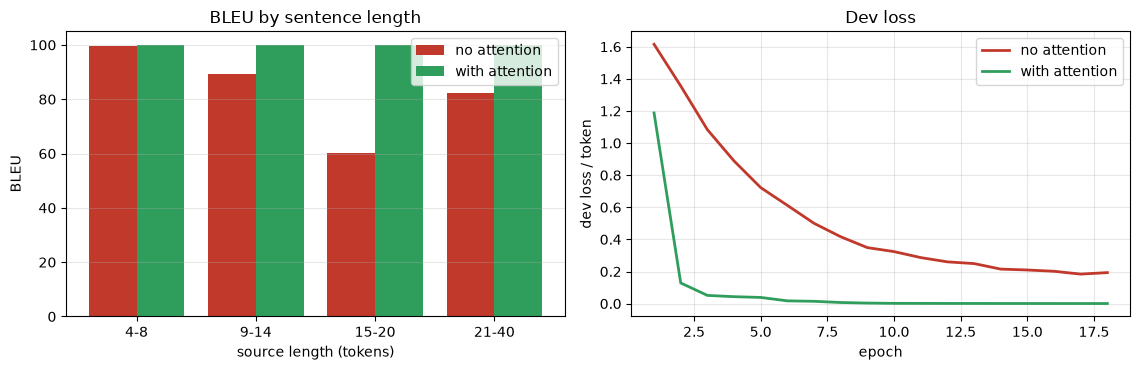

In [54]:
import matplotlib
matplotlib.rcParams["axes.unicode_minus"] = False
import matplotlib.pyplot as plt

ks = [k for k in RES_PLAIN["by_len"] if k in RES_ATTN["by_len"]]
labels = [f"{lo}-{hi}" for lo, hi in ks]
v_plain = [RES_PLAIN["by_len"][k] for k in ks]
v_attn = [RES_ATTN["by_len"][k] for k in ks]
xpos = np.arange(len(ks))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].bar(xpos - 0.2, v_plain, 0.4, label="no attention", color="#C0392B")
ax[0].bar(xpos + 0.2, v_attn, 0.4, label="with attention", color="#2F9E5C")
ax[0].set_xticks(xpos); ax[0].set_xticklabels(labels)
ax[0].set_xlabel("source length (tokens)"); ax[0].set_ylabel("BLEU")
ax[0].set_title("BLEU by sentence length"); ax[0].legend(); ax[0].grid(axis="y", alpha=.3)

ax[1].plot([h[0] for h in hist_plain], [h[2] for h in hist_plain],
           color="#C0392B", lw=2, label="no attention")
ax[1].plot([h[0] for h in hist_attn], [h[2] for h in hist_attn],
           color="#2F9E5C", lw=2, label="with attention")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("dev loss / token")
ax[1].set_title("Dev loss"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

---
# ส่วนที่ 12 — Attention Visualization (Heatmap)

นี่คือ "ผลพลอยได้ฟรี" ของ attention: เราอ่านได้ว่าคำแปลแต่ละคำมองคำต้นทางคำไหน
สิ่งที่ควรเห็นคือ **แนวทแยงที่ข้ามกัน** ตรงคู่ "คำนาม + คำขยาย"
เพราะไทยเรียง `แมว ดำ` แต่อังกฤษเรียง `black cats`

### ✏️ TODO 14 — ดึงเมทริกซ์ attention และวาด heatmap

In [55]:
@torch.no_grad()
def decode_with_attention(enc, dec, src_tokens, max_len=45):
    """
    เหมือน greedy_decode แต่เก็บเวกเตอร์ attention ของทุกขั้นด้วย
    คืน (hyp_tokens, A) โดย A มีรูปร่าง (len(hyp), len(src))
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 14a: decode_with_attention()")
    # ==============================================


def plot_attention(src_tokens, hyp_tokens, A):
    """วาด heatmap — แกน x = คำต้นทาง, แกน y = คำที่สร้าง
    หมายเหตุ: ฟอนต์เริ่มต้นของ matplotlib ไม่รองรับอักษรไทย จึงใช้ตัวเลขกำกับตำแหน่งแทน"""
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 14b: plot_attention()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 14</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

ต้นทาง : 1:ฉัน 2:ชอบ 3:แมว 4:ดำ 5:และ 6:หมา 7:ขาว
ทำนาย  : i liked black cats and white dogs

ตารางน้ำหนัก attention:
                   1       2       3       4       5       6       7
                 ฉัน     ชอบ     แมว      ดำ     และ     หมา     ขาว
  i             1.00    0.00    0.00    0.00    0.00    0.00    0.00
  liked         0.01    0.99    0.00    0.00    0.00    0.00    0.00
  black         0.00    0.00    0.00    1.00    0.00    0.00    0.00
  cats          0.00    0.00    1.00    0.00    0.00    0.00    0.00
  and           0.00    0.00    0.00    0.00    0.99    0.01    0.00
  white         0.00    0.00    0.00    0.00    0.00    0.00    1.00
  dogs          0.00    0.00    0.00    0.00    0.00    1.00    0.00

การจับคู่ที่โมเดลเรียนรู้ได้เอง (argmax ของแต่ละแถว):
  i          -> ตำแหน่ง 1 = 'ฉัน'   (น้ำหนัก 1.00)
  liked      -> ตำแหน่ง 2 = 'ชอบ'   (น้ำหนัก 0.99)
  black      -> ตำแหน่ง 4 = 'ดำ'   (น้ำหนัก 1.00)
  cats       -> ตำแหน่ง 3 = 'แมว'   (น้ำหนัก 1.00)
  a

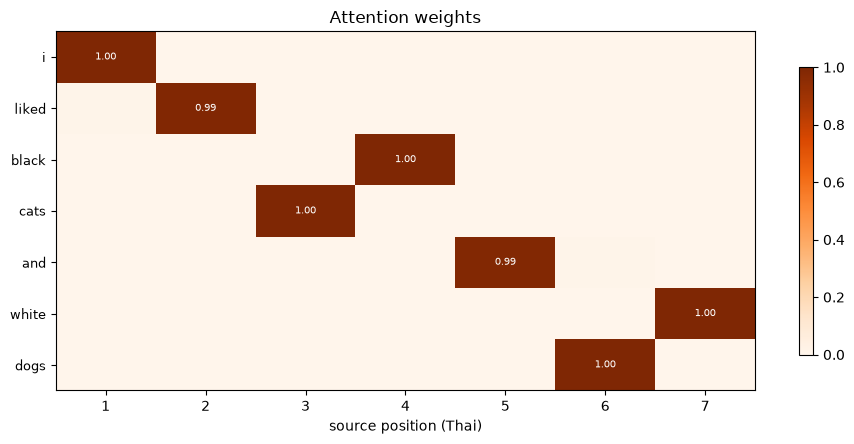


ตรวจการจับคู่ที่ข้ามกัน:
  black    -> 'ดำ'  (คาดหวัง 'ดำ')  ✓
  cats     -> 'แมว'  (คาดหวัง 'แมว')  ✓
  white    -> 'ขาว'  (คาดหวัง 'ขาว')  ✓
  dogs     -> 'หมา'  (คาดหวัง 'หมา')  ✓

✅ ผ่าน — attention เรียนรู้การสลับลำดับ 'แมว ดำ' -> 'black cats' ได้เอง โดยไม่มีกฎ reordering ใด ๆ


In [56]:
@torch.no_grad()
def decode_with_attention(enc, dec, src_tokens, max_len=45):
    enc.eval(); dec.eval()
    x = torch.tensor([[SRC_STOI.get(w, 3) for w in src_tokens]], device=DEVICE)
    x_len = torch.tensor([x.size(1)])
    H, hidden = enc(x, x_len)
    mask = (x != PAD_ID)
    tok, out, rows = BOS_ID, [], []
    for _ in range(max_len):
        logits, hidden, a = dec(torch.tensor([[tok]], device=DEVICE), hidden, H, mask)
        tok = int(logits[0, -1].argmax())
        w = TGT_ITOS[tok]
        if w == EOS:
            break
        out.append(w)
        rows.append(a[0, -1].cpu().numpy())
    return out, (np.stack(rows) if rows else np.zeros((0, len(src_tokens))))


def plot_attention(src_tokens, hyp_tokens, A):
    fig, ax = plt.subplots(figsize=(1.0 * len(src_tokens) + 2.5,
                                    0.42 * len(hyp_tokens) + 1.6))
    im = ax.imshow(A, cmap="Oranges", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(src_tokens)))
    ax.set_xticklabels([f"{i+1}" for i in range(len(src_tokens))])
    ax.set_yticks(range(len(hyp_tokens)))
    ax.set_yticklabels(hyp_tokens, fontsize=9)
    ax.set_xlabel("source position (Thai)")
    ax.set_title("Attention weights")
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            if A[i, j] > 0.15:
                ax.text(j, i, f"{A[i, j]:.2f}", ha="center", va="center",
                        fontsize=7, color="white" if A[i, j] > 0.55 else "#5B6478")
    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout(); plt.show()


SRC_DEMO = "ฉัน ชอบ แมว ดำ และ หมา ขาว".split()
hyp_demo, A_demo = decode_with_attention(enc_attn, dec_attn, SRC_DEMO)

print("ต้นทาง :", " ".join(f"{i+1}:{w}" for i, w in enumerate(SRC_DEMO)))
print("ทำนาย  :", " ".join(hyp_demo))
print("\nตารางน้ำหนัก attention:")
print("  " + " " * 10 + "".join(f"{i+1:>8}" for i in range(len(SRC_DEMO))))
print("  " + " " * 10 + "".join(f"{w:>8}" for w in SRC_DEMO))
for w, row in zip(hyp_demo, A_demo):
    print(f"  {w:<10}" + "".join(f"{v:>8.2f}" for v in row))

print("\nการจับคู่ที่โมเดลเรียนรู้ได้เอง (argmax ของแต่ละแถว):")
for w, row in zip(hyp_demo, A_demo):
    j = int(np.argmax(row))
    print(f"  {w:<10} -> ตำแหน่ง {j+1} = '{SRC_DEMO[j]}'   (น้ำหนัก {row[j]:.2f})")

plot_attention(SRC_DEMO, hyp_demo, A_demo)

# 🔍 ตรวจคำตอบ — ต้องเห็นการจับคู่ที่ข้ามกัน
peak = {w: int(np.argmax(r)) for w, r in zip(hyp_demo, A_demo)}
print("\nตรวจการจับคู่ที่ข้ามกัน:")
ok = True
for en_w, th_w in [("black", "ดำ"), ("cats", "แมว"), ("white", "ขาว"), ("dogs", "หมา")]:
    if en_w in peak:
        got = SRC_DEMO[peak[en_w]]
        mark = "✓" if got == th_w else "✗"
        print(f"  {en_w:<8} -> '{got}'  (คาดหวัง '{th_w}')  {mark}")
        ok &= (got == th_w)
assert "black" in peak and "cats" in peak, "โมเดลควรสร้าง black และ cats ได้"
assert peak["black"] > peak["cats"], (
    "ต้องเห็นการข้ามกัน: 'black' ควรชี้ไปตำแหน่งที่อยู่ *หลัง* ตำแหน่งของ 'cats'")
print("\n✅ ผ่าน — attention เรียนรู้การสลับลำดับ 'แมว ดำ' -> 'black cats' ได้เอง"
      " โดยไม่มีกฎ reordering ใด ๆ")

---
# ส่วนที่ 13 — Coverage Mechanism

$$cov_t = \sum_{t' < t} a_{t'} \qquad covloss_t = \sum_s \min\big(a_t(s),\ cov_t(s)\big)$$

`min(a, cov)` จะมีค่ามากเมื่อ "กำลังสนใจ" ทับกับ "ที่สนใจไปแล้ว"
จึงเป็นการลงโทษการแปลซ้ำ (over-translation) และผลักให้ความสนใจกระจายครอบคลุมทุกคำต้นทาง

### ✏️ TODO 15 — coverage loss

In [57]:
def coverage_loss(A):
    """
    A : เมทริกซ์ attention (T_y, T_x) — numpy array หรือ torch tensor
    คืน (total_loss, per_step_list) โดยที่ขั้นแรกต้องได้ 0 เสมอ (ยังไม่มีอะไรสะสม)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 15: coverage_loss()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 15</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [58]:
def coverage_loss(A):
    A = np.asarray(A, dtype=float)
    cov = np.zeros(A.shape[1])
    per_step, total = [], 0.0
    for a in A:
        l = float(np.minimum(a, cov).sum())
        per_step.append(l)
        total += l
        cov = cov + a
    return total, per_step


# --- ตรวจกับตัวเลขในสไลด์ที่ 38 ---
A_slide = np.array([[0.05, 0.05, 0.10, 0.80],
                    [0.05, 0.05, 0.10, 0.80],     # สนใจ "ดำ" ซ้ำ
                    [0.60, 0.20, 0.10, 0.10]])
tot, per = coverage_loss(A_slide)
cov = np.zeros(4)
print(f"  {'t':>3}{'a_t':>28}{'cov_t (สะสม)':>30}{'covloss':>11}")
print("  " + "-" * 74)
for i, (a, l) in enumerate(zip(A_slide, per), 1):
    print(f"  {i:>3}{str(np.round(a,2)):>28}{str(np.round(cov,2)):>30}{l:>11.4f}")
    cov = cov + a
print(f"\n  รวม coverage loss = {tot:.4f}")
print("  -> ขั้นที่ 2 ถูกลงโทษเต็มที่ (1.0000) เพราะไปสนใจ 'ดำ' ซ้ำ")

# --- ใช้กับ attention จริงจากโมเดลของเรา ---
tot_real, per_real = coverage_loss(A_demo)
print(f"\n  coverage loss ของโมเดลที่เราฝึก (ประโยค 7 คำ) = {tot_real:.4f}")
print(f"  ค่าต่อขั้น: {[round(v, 3) for v in per_real]}")
print("  -> ต่ำมาก เพราะโมเดลกระจายความสนใจไปคนละตำแหน่งในแต่ละขั้นอยู่แล้ว")

# 🔍 ตรวจคำตอบ — ตรงกับสไลด์ที่ 38
assert abs(per[0] - 0.0) < 1e-9, "ขั้นแรกต้องได้ 0"
assert abs(per[1] - 1.0) < 1e-9, per[1]
assert abs(per[2] - 0.4) < 1e-9, per[2]
assert abs(tot - 1.4) < 1e-9
assert tot_real < 1.0, "attention ที่ดีควรมี coverage loss ต่ำ"
print("\n✅ ผ่าน — ตรงกับสไลด์ที่ 38 ทุกตัว")

    t                         a_t                  cov_t (สะสม)    covloss
  --------------------------------------------------------------------------
    1       [0.05 0.05 0.1  0.8 ]                 [0. 0. 0. 0.]     0.0000
    2       [0.05 0.05 0.1  0.8 ]         [0.05 0.05 0.1  0.8 ]     1.0000
    3           [0.6 0.2 0.1 0.1]             [0.1 0.1 0.2 1.6]     0.4000

  รวม coverage loss = 1.4000
  -> ขั้นที่ 2 ถูกลงโทษเต็มที่ (1.0000) เพราะไปสนใจ 'ดำ' ซ้ำ

  coverage loss ของโมเดลที่เราฝึก (ประโยค 7 คำ) = 0.0282
  ค่าต่อขั้น: [0.0, 0.011, 0.001, 0.003, 0.0, 0.002, 0.011]
  -> ต่ำมาก เพราะโมเดลกระจายความสนใจไปคนละตำแหน่งในแต่ละขั้นอยู่แล้ว

✅ ผ่าน — ตรงกับสไลด์ที่ 38 ทุกตัว


---
# ส่วนที่ 14 — สรุปผลทั้งหมด

### ✏️ TODO 16 — สร้างตารางสรุป

In [59]:
def final_summary():
    """
    พิมพ์ตารางสรุปเทียบทุกการตั้งค่าที่เราทดลอง (BLEU, chrF2, exact match)
    แล้วคืนลิสต์ของ (ชื่อ, bleu, chrf, exact)
    """
    # ============ เขียนโค้ดของคุณตรงนี้ ============
    raise NotImplementedError("TODO 16: final_summary()")
    # ==============================================

<details>
<summary><b>✅ เฉลย TODO 16</b> </summary>

เซลล์ถัดไปคือเฉลย — รันแล้วจะเขียนทับฟังก์ชันของคุณ

</details>

In [60]:
def final_summary():
    rows = []
    print(f"{'ระบบ':<42}{'BLEU':>8}{'chrF2':>9}{'exact':>9}")
    print("=" * 68)

    # baseline greedy / beam (บนชุดย่อย 120 ประโยค)
    for nm, bl, cf, ex in rows_dec:
        rows.append((f"ไม่มี attention — {nm}", bl, cf, ex))

    print("  [ประเมินบนชุดทดสอบย่อย 120 ประโยค]")
    for nm, bl, cf, ex in rows_dec:
        print(f"{'ไม่มี attention — ' + nm:<42}{bl:>8.2f}{cf:>9.2f}{ex:>8.1%}")

    print("\n  [ประเมินบนชุดทดสอบเต็ม 300 ประโยค, greedy]")
    for nm, r in [("ไม่มี attention", RES_PLAIN), ("มี attention (global, general)", RES_ATTN)]:
        rows.append((nm, r["bleu"], r["chrf"], r["exact"]))
        print(f"{nm:<42}{r['bleu']:>8.2f}{r['chrf']:>9.2f}{r['exact']:>8.1%}")
    return rows


ROWS = final_summary()

print("\n" + "=" * 68)
print("ข้อสรุปสี่ข้อที่ Lab นี้พิสูจน์ได้ด้วยข้อมูลของเราเอง")
print("=" * 68)
print(f"1. คอขวดมีจริง — baseline ตกจาก BLEU {RES_PLAIN['by_len'][(4,8)]:.1f} "
      f"(ประโยค 4-8 คำ) เหลือ {RES_PLAIN['by_len'][(15,20)]:.1f} (ประโยค 15-20 คำ)")
print(f"2. Beam search ช่วยได้จริง — {rows_dec[0][1]:.2f} -> {rows_dec[2][1]:.2f} BLEU")
print(f"3. พิมพ์ตกหนึ่งตัวอักษร -> BLEU-4 {tbl[0][1]:.2f} ตกเป็น {tbl[1][1]:.2f} (ลด 100%) "
      f"แต่ chrF2 ลดเพียง {tbl[0][3]:.2f} -> {tbl[1][3]:.2f} ({d_chrf/tbl[0][3]:.1%})")
print(f"4. Attention แก้ปัญหาความยาวได้ — ประโยค 15-20 คำ ดีขึ้น "
      f"{RES_ATTN['by_len'][(15,20)] - RES_PLAIN['by_len'][(15,20)]:+.1f} BLEU "
      f"ขณะที่ประโยคสั้นดีขึ้นเพียง "
      f"{RES_ATTN['by_len'][(4,8)] - RES_PLAIN['by_len'][(4,8)]:+.1f}")

# 🔍 ตรวจคำตอบ
assert len(ROWS) == 5
print("\n✅ ผ่าน")

ระบบ                                          BLEU    chrF2    exact
  [ประเมินบนชุดทดสอบย่อย 120 ประโยค]
ไม่มี attention — greedy                     74.48    84.31   55.8%
ไม่มี attention — beam k=5 (alpha=0, ไม่ norm)   74.67    85.04   58.3%
ไม่มี attention — beam k=5 (alpha=1, normalize)   76.03    86.29   60.8%

  [ประเมินบนชุดทดสอบเต็ม 300 ประโยค, greedy]
ไม่มี attention                              75.78    85.37   59.3%
มี attention (global, general)              100.00   100.00  100.0%

ข้อสรุปสี่ข้อที่ Lab นี้พิสูจน์ได้ด้วยข้อมูลของเราเอง
1. คอขวดมีจริง — baseline ตกจาก BLEU 99.5 (ประโยค 4-8 คำ) เหลือ 60.2 (ประโยค 15-20 คำ)
2. Beam search ช่วยได้จริง — 74.48 -> 76.03 BLEU
3. พิมพ์ตกหนึ่งตัวอักษร -> BLEU-4 51.54 ตกเป็น 0.00 (ลด 100%) แต่ chrF2 ลดเพียง 80.80 -> 77.20 (4.5%)
4. Attention แก้ปัญหาความยาวได้ — ประโยค 15-20 คำ ดีขึ้น +39.8 BLEU ขณะที่ประโยคสั้นดีขึ้นเพียง +0.5

✅ ผ่าน


### 📊 กราฟสรุป

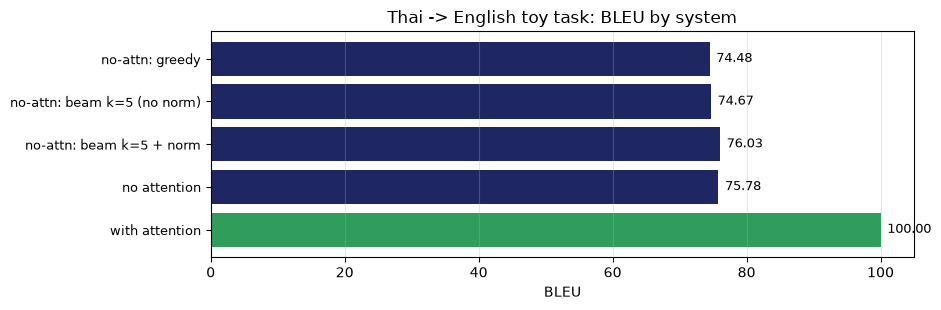

In [61]:
names = [r[0] for r in ROWS]
bleus = [r[1] for r in ROWS]
short = [n.replace("ไม่มี attention — ", "no-attn: ")
          .replace("ไม่มี attention", "no attention")
          .replace("มี attention (global, general)", "with attention")
          .replace("beam k=5 (alpha=0, ไม่ norm)", "beam k=5 (no norm)")
          .replace("beam k=5 (alpha=1, normalize)", "beam k=5 + norm")
         for n in names]
colors = ["#2F9E5C" if "with attention" in s else "#1E2761" for s in short]

fig, ax = plt.subplots(figsize=(9.5, 3.2))
bars = ax.barh(range(len(short)), bleus, color=colors)
ax.set_yticks(range(len(short))); ax.set_yticklabels(short, fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("BLEU"); ax.set_xlim(0, 105)
ax.set_title("Thai -> English toy task: BLEU by system")
for b, v in zip(bars, bleus):
    ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.2f}", va="center", fontsize=9)
ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()